# AWS First Task: Market Arrivals Analysis

## Importing Important Libraries
For our data processing and analysis task, we need:
- **requests**: to fetch raw data from the internet
- **pandas**: to save/load CSV files and clean the raw data
- **numpy**: to perform vectorised statistical operations on the data
- **matplotlib**: to provide visual representations of data statistics

In [1]:
# imports
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Fetching from Internet and Saving Raw Data for Offline Use

In [3]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/MarketArrivals.csv"
try:
    df = pd.read_csv(url)
    df.to_csv("marketing.csv", index=False)
    print("fetched and saved marketing.csv")
except Exception as e:
    print("Eroor: ", e)

fetched and saved marketing.csv


### Load, Clean, and Inspect Dataset Shape & Structure

In [4]:
def read_clean_data():
    df = pd.read_csv("marketing.csv")
    df.drop(columns=['month', 'year'], inplace=True)
    df['date'] = pd.to_datetime(df['date'], format='mixed', dayfirst=False, errors='coerce')
    return df

df = read_clean_data()

# Shape and Structural Analysis
print("DATASET SHAPE & STRUCTURE")
print(f"Shape (Rows, Cols) : {df.shape}\n")

print("Column Data Types:")
print(df.dtypes.to_string())

print("\nMissing Values Per Column:")
print(df.isna().sum().to_string())

display(df.head())
display(df.describe().round(1))

📐 DATASET SHAPE & STRUCTURE
Total Rows (Records)    : 10227
Total Columns           : 8
Full Shape (Rows, Cols) : (10227, 8)

📋 Column Data Types:
market                 str
quantity             int64
priceMin             int64
priceMax             int64
priceMod             int64
state                  str
city                   str
date        datetime64[us]

🔍 Missing Values Per Column:
market      0
quantity    0
priceMin    0
priceMax    0
priceMod    0
state       0
city        0
date        0


,market,quantity,priceMin,priceMax,priceMod,state,city,date
0,ABOHAR(PB),2350,404,493,446,PB,ABOHAR,2005-01-01
1,ABOHAR(PB),900,487,638,563,PB,ABOHAR,2006-01-01
2,ABOHAR(PB),790,1283,1592,1460,PB,ABOHAR,2010-01-01
3,ABOHAR(PB),245,3067,3750,3433,PB,ABOHAR,2011-01-01
4,ABOHAR(PB),1035,523,686,605,PB,ABOHAR,2012-01-01


,quantity,priceMin,priceMax,priceMod,date
count,10227.0,10227.0,10227.0,10227.0,10227
mean,76604.9,646.9,1212.8,984.3,2009-06-22 18:57:58.556761
min,20.0,16.0,145.0,80.0,1996-01-01 00:00:00
25%,8898.0,209.0,557.0,448.0,2006-04-01 00:00:00
50%,27460.0,440.0,923.0,747.0,2009-11-01 00:00:00
75%,88356.5,828.0,1527.0,1248.0,2013-03-01 00:00:00
max,1639032.0,6000.0,8192.0,6400.0,2016-02-01 00:00:00
std,124408.7,673.1,979.7,818.5,NaN


### Initial Plotting: Visualizing Price and Quantity Trends

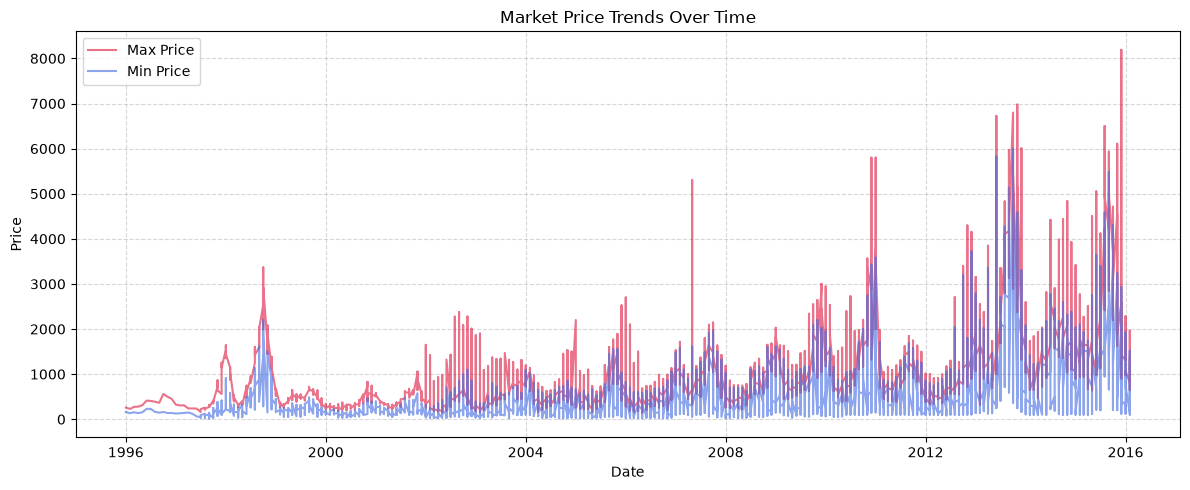

In [5]:
# Sort by date for proper time-series plotting
df_sorted = df.sort_values('date').dropna(subset=['date'])

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df_sorted['date'], df_sorted['priceMax'], color='crimson', alpha=0.6, label='Max Price')
ax1.plot(df_sorted['date'], df_sorted['priceMin'], color='royalblue', alpha=0.6, label='Min Price')
ax1.set_xlabel('Date')
ax1.set_ylabel('Price', color='black')
ax1.set_title('Market Price Trends Over Time')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [6]:
# NumPy Statistical Operations
max_prices = df['priceMax'].to_numpy()
min_prices = df['priceMin'].to_numpy()

print(f"The highest max price : {max_prices.max()} on date: {df['date'].iloc[max_prices.argmax()].date()}")
print(f"The lowest max price  : {max_prices.min()} on date: {df['date'].iloc[max_prices.argmin()].date()}")
print(f"The average max price : {max_prices.mean():.1f}")

low_price_days = (min_prices < 100).sum()
print(f"Days with very low min prices (< 100): {int(low_price_days)} out of {len(min_prices)} days.")

The highest max price : 8192 on date: 2015-12-01
The lowest max price  : 145 on date: 2006-05-01
The average max price : 1212.8
Days with very low min prices (< 100): 615 out of 10227 days.
